Day 1 and 2

Step 1 — Load and inspect the dataset
Open your Python environment or Jupyter Notebook and make sure Dataset 2 is available. Run the following code.

In [1]:
import pandas as pd

# Load the CareFlow dataset
df = pd.read_csv("Careflowdataset.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (9855, 9)

Columns:
['Case ID', 'Event Index', 'Activity', 'Timestamp', 'Next Activity', 'Elapsed to Next (min)', 'Resource', 'Department', 'Status']

First 5 rows:
         Case ID  Event Index                      Activity  \
0  PAT-2026-9840            1      ED Registration & Triage   
1  PAT-2026-9840            2  Initial Physician Assessment   
2  PAT-2026-9840            3  Stat Blood Draw & Biomarkers   
3  PAT-2026-9644            1      ED Registration & Triage   
4  PAT-2026-9644            2  Initial Physician Assessment   

                  Timestamp                    Next Activity  \
0  2026-09-12T08:00:00.000Z     Initial Physician Assessment   
1  2026-09-12T08:10:00.000Z     Stat Blood Draw & Biomarkers   
2  2026-09-12T08:25:00.000Z  Central Laboratory Specimen Run   
3  2026-09-12T08:28:00.000Z     Initial Physician Assessment   
4  2026-09-12T08:52:00.000Z     Stat Blood Draw & Biomarkers   

   Elapsed to Next (min)                 Resource       

Step 2 — Verify event ordering
We need to check whether each patient's events are ordered correctly by Event Index, and whether their timestamps are chronological.

How to interpret the results:
- Duplicate event indices should be investigated.
- Out-of-order timestamps should be investigated.
- A zero result for both checks is a good sign, but it doesn't by itself prove that the entire event log is correct.

In [2]:
# Sort events within each patient case
df = df.sort_values(
    by=["Case ID", "Event Index"]
).reset_index(drop=True)

# Check for duplicate event indices within a case
duplicate_events = df.duplicated(
    subset=["Case ID", "Event Index"],
    keep=False
)

print("Rows with duplicate event indices:",
      duplicate_events.sum())

# Check whether timestamps are chronological within each case
df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True)

timestamp_diff = (
    df.groupby("Case ID")["Timestamp"].diff()
)

out_of_order = timestamp_diff < pd.Timedelta(0)

print("Cases with out-of-order timestamps:",
      df.loc[out_of_order, "Case ID"].nunique())

print("Events with out-of-order timestamps:",
      out_of_order.sum())

Rows with duplicate event indices: 0
Cases with out-of-order timestamps: 0
Events with out-of-order timestamps: 0


Step 3 — Verify the activity sequence
Now we will compare the Next Activity column with the activity actually recorded in the next event.

In [ ]:
# Get the next recorded activity within each case
df["Actual Next Activity"] = (
    df.groupby("Case ID")["Activity"].shift(-1)
)

# Compare the recorded next activity with the actual next event
has_next = df["Actual Next Activity"].notna()

matches = (
    df.loc[has_next, "Next Activity"]
    == df.loc[has_next, "Actual Next Activity"]
)

print("Events with a subsequent event:", has_next.sum())
print("Matching next activities:", matches.sum())
print("Mismatches:", (~matches).sum())

# Display mismatches for investigation
mismatches = df.loc[
    has_next & (df["Next Activity"] != df["Actual Next Activity"]),
    ["Case ID", "Event Index", "Activity",
     "Next Activity", "Actual Next Activity"]
]

print(mismatches.head(20))

Events with a subsequent event: 8427
Matching next activities: 8427
Mismatches: 0
Empty DataFrame
Columns: [Case ID, Event Index, Activity, Next Activity, Actual Next Activity]
Index: []


Step 4 — Display complete patient journeys
Let's create a readable activity sequence for each case.

In [ ]:
journeys = (
    df.groupby("Case ID")["Activity"]
    .agg(list)
)

print("Sample patient journeys:\n")

for case_id, activities in journeys.head(10).items():
    print(f"{case_id}: {' -> '.join(activities)}")

Sample patient journeys:

PAT-2026-10000: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10001: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10002: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Sub-Specialist On-Call Consult -> Empiric Antibiotic / Targeted Therapy -> Direct ICU Bed Transfer
PAT-2026-10003: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10004: ED Registration & Triage -> Initial Physi

# Day 3: Exploratory Data Analysis

In [ ]:
import pandas as pd

# Load the CareFlow dataset
df = pd.read_csv("/content/Careflowdataset.csv")

# Dataset overview
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset shape: (9855, 9)

Column names:
['Case ID', 'Event Index', 'Activity', 'Timestamp', 'Next Activity', 'Elapsed to Next (min)', 'Resource', 'Department', 'Status']

Data types:
Case ID                   object
Event Index                int64
Activity                  object
Timestamp                 object
Next Activity             object
Elapsed to Next (min)    float64
Resource                  object
Department                object
Status                    object
dtype: object

Missing values per column:
Case ID                     0
Event Index                 0
Activity                    0
Timestamp                   0
Next Activity            1428
Elapsed to Next (min)    1428
Resource                    0
Department                  0
Status                      0
dtype: int64

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Case ID,9855,1428,PAT-2026-9308,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event Index,9855.0,NaN,NaN,NaN,4.029731,2.114595,1.0,2.0,4.0,6.0,9.0
Activity,9855,11,Stat Blood Draw & Biomarkers,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Timestamp,9855,6500,2026-09-25T19:58:00.000Z,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Next Activity,8427,10,Stat Blood Draw & Biomarkers,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Elapsed to Next (min),8427.0,NaN,NaN,NaN,42.894268,26.789889,10.0,21.0,30.0,59.0,104.0
Resource,9855,15,Pathology Tech Kowalski,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,9855,6,Emergency Medicine,4456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,9855,9,Completed,4284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Count how often each activity occurs
activity_counts = df["Activity"].value_counts()

print("Activity Frequency:\n")
print(activity_counts)

Activity Frequency:

Activity
Stat Blood Draw & Biomarkers             1600
Central Laboratory Specimen Run          1600
ED Registration & Triage                 1428
Initial Physician Assessment             1428
Empiric Antibiotic / Targeted Therapy    1428
Inpatient Ward Bed Handover               819
Diagnostic CT / Angiography Imaging       571
Discharge to Outpatient Care              409
Sub-Specialist On-Call Consult            200
Direct ICU Bed Transfer                   200
Specimen Hemolysis / Re-draw Order        172
Name: count, dtype: int64


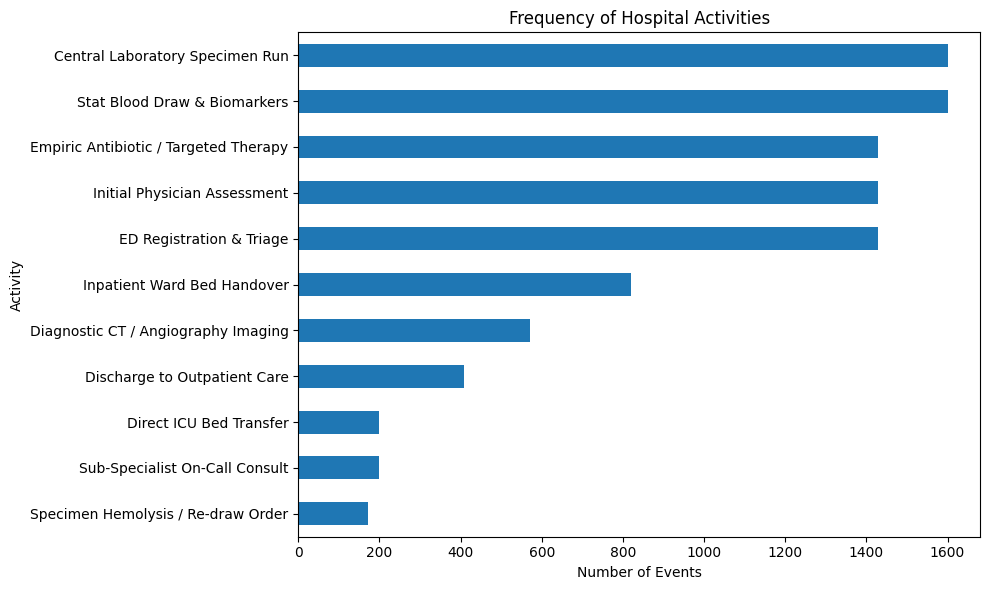

In [ ]:
import matplotlib.pyplot as plt

activity_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Frequency of Hospital Activities"
)

plt.xlabel("Number of Events")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

In [ ]:
# Count the number of events in each patient case
events_per_case = df.groupby("Case ID")["Event Index"].count()

print("Events per patient case:")
print(events_per_case.describe())

print("\nNumber of events per case:")
print(events_per_case.value_counts().sort_index())

Events per patient case:
count    1428.000000
mean        6.901261
std         1.045254
min         6.000000
25%         6.000000
50%         7.000000
75%         8.000000
max         9.000000
Name: Event Index, dtype: float64

Number of events per case:
Event Index
6    685
7    371
8    200
9    172
Name: count, dtype: int64


In [ ]:
# Sort events within each case
df_sorted = df.sort_values(
    ["Case ID", "Event Index"]
)

# Create one activity sequence per case
journeys = df_sorted.groupby("Case ID")["Activity"].agg(
    lambda activities: " -> ".join(activities)
)

# Count repeated journey patterns
journey_counts = journeys.value_counts()

print("Top 10 most common patient journeys:")
display(journey_counts.head(10).rename_axis("Patient Journey").reset_index(name="Case Count"))

Top 10 most common patient journeys:


,Patient Journey,Case Count
0,ED Registration & Triage -> Initial Physician ...,457
1,ED Registration & Triage -> Initial Physician ...,247
2,ED Registration & Triage -> Initial Physician ...,228
3,ED Registration & Triage -> Initial Physician ...,200
4,ED Registration & Triage -> Initial Physician ...,124
5,ED Registration & Triage -> Initial Physician ...,115
6,ED Registration & Triage -> Initial Physician ...,57


In [ ]:
# Display complete journey patterns without truncation
pd.set_option("display.max_colwidth", None)

top_journeys = (
    journey_counts.head(10)
    .rename_axis("Patient Journey")
    .reset_index(name="Case Count")
)

display(top_journeys)


,Patient Journey,Case Count
0,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,457
1,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,247
2,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,228
3,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Sub-Specialist On-Call Consult -> Empiric Antibiotic / Targeted Therapy -> Direct ICU Bed Transfer,200
4,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,124
5,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Specimen Hemolysis / Re-draw Order -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,115
6,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Specimen Hemolysis / Re-draw Order -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,57


In [ ]:
# Convert elapsed time to numeric, if necessary
df["Elapsed to Next (min)"] = pd.to_numeric(
    df["Elapsed to Next (min)"],
    errors="coerce"
)

# Overall summary of recorded transition durations
print("Transition-time summary:")
display(df["Elapsed to Next (min)"].describe())

# Average duration by activity
transition_summary = (
    df.dropna(subset=["Elapsed to Next (min)"])
      .groupby("Activity")["Elapsed to Next (min)"]
      .agg(["count", "mean", "median", "max"])
      .sort_values("mean", ascending=False)
)

print("\nTransition duration by current activity:")
display(transition_summary.round(2))

Transition-time summary:


,Elapsed to Next (min)
count,8427.000000
mean,42.894268
std,26.789889
min,10.000000
25%,21.000000
50%,30.000000
75%,59.000000
max,104.000000



Transition duration by current activity:


,count,mean,median,max
Activity,,,,
Empiric Antibiotic / Targeted Therapy,1428,89.44,89.0,104.0
Stat Blood Draw & Biomarkers,1600,49.31,48.0,59.0
Diagnostic CT / Angiography Imaging,571,43.98,31.0,88.0
Central Laboratory Specimen Run,1600,40.25,30.0,79.0
Sub-Specialist On-Call Consult,200,26.88,27.0,34.0
Specimen Hemolysis / Re-draw Order,172,25.00,25.0,25.0
Initial Physician Assessment,1428,21.99,22.0,29.0
ED Registration & Triage,1428,16.99,17.0,24.0


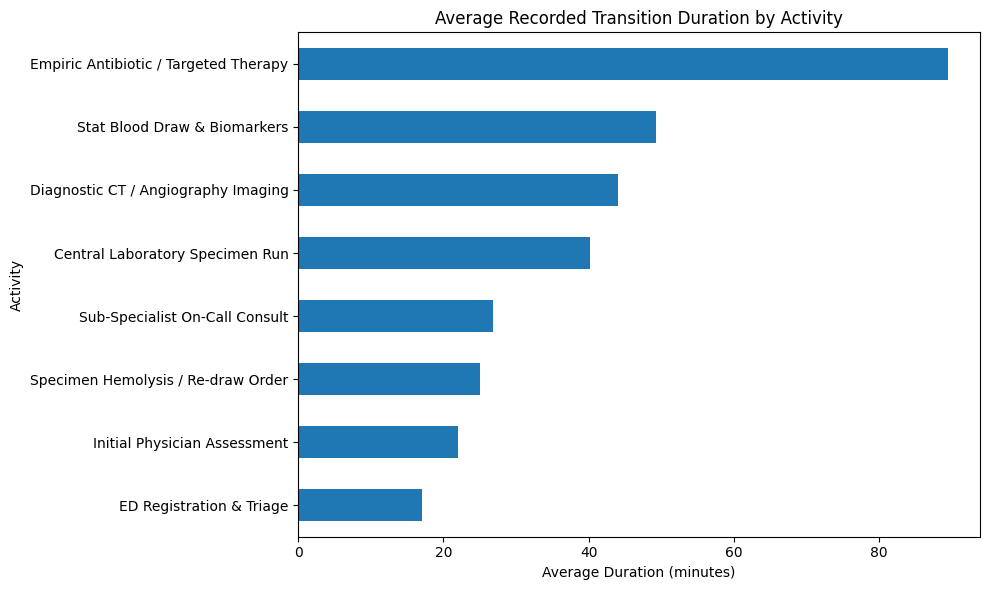

In [ ]:
import matplotlib.pyplot as plt

transition_summary["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Recorded Transition Duration by Activity"
)

plt.xlabel("Average Duration (minutes)")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

# Day 4 to Day 7: Transition-Time Analysis and Potential Bottlenecks

In [ ]:
# Check missing transition durations
elapsed_col = "Elapsed to Next (min)"

print("Total event records:", len(df))
print("Missing transition durations:", df[elapsed_col].isna().sum())
print("Available transition durations:", df[elapsed_col].notna().sum())

# Convert values to numeric safely
df[elapsed_col] = pd.to_numeric(df[elapsed_col], errors="coerce")

# Summarize recorded transition durations
print("\nTransition Duration Summary:")
display(df[elapsed_col].describe().to_frame().round(2))

# Check for zero or negative durations
print("\nZero-duration records:", (df[elapsed_col] == 0).sum())
print("Negative-duration records:", (df[elapsed_col] < 0).sum())

Total event records: 9855
Missing transition durations: 1428
Available transition durations: 8427

Transition Duration Summary:


,Elapsed to Next (min)
count,8427.00
mean,42.89
std,26.79
min,10.00
25%,21.00
50%,30.00
75%,59.00
max,104.00



Zero-duration records: 0
Negative-duration records: 0


In [ ]:
# Get the longest recorded transitions
longest_transitions = (
    df.dropna(subset=["Elapsed to Next (min)"])
      .sort_values("Elapsed to Next (min)", ascending=False)
      [["Case ID", "Activity", "Next Activity",
        "Elapsed to Next (min)"]]
)

print("Top 10 longest recorded transitions:")
display(longest_transitions.head(10))

Top 10 longest recorded transitions:


,Case ID,Activity,Next Activity,Elapsed to Next (min)
9847,PAT-2026-9839,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
4100,PAT-2026-9179,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
4102,PAT-2026-10019,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
4665,PAT-2026-9209,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
1171,PAT-2026-9899,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
3959,PAT-2026-9599,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
8370,PAT-2026-9779,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
4666,PAT-2026-10049,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0
9744,PAT-2026-10259,Empiric Antibiotic / Targeted Therapy,Direct ICU Bed Transfer,104.0
8952,PAT-2026-9809,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,104.0


In [ ]:
transition_stats = (
    df.dropna(subset=["Next Activity", "Elapsed to Next (min)"])
      .groupby(["Activity", "Next Activity"])["Elapsed to Next (min)"]
      .agg(["count", "mean", "median", "max"])
      .sort_values("mean", ascending=False)
      .round(2)
)

print("Transitions ranked by average elapsed duration:")
display(transition_stats.head(10))

Transitions ranked by average elapsed duration:


count  \
Activity                              Next Activity                                  
Empiric Antibiotic / Targeted Therapy Inpatient Ward Bed Handover              819   
                                      Direct ICU Bed Transfer                  200   
                                      Discharge to Outpatient Care             409   
Diagnostic CT / Angiography Imaging   Sub-Specialist On-Call Consult           200   
Central Laboratory Specimen Run       Diagnostic CT / Angiography Imaging      571   
Stat Blood Draw & Biomarkers          Central Laboratory Specimen Run         1600   
Diagnostic CT / Angiography Imaging   Empiric Antibiotic / Targeted Therapy    371   
Central Laboratory Specimen Run       Empiric Antibiotic / Targeted Therapy    857   
Sub-Specialist On-Call Consult        Empiric Antibiotic / Targeted Therapy    200   
Specimen Hemolysis / Re-draw Order    Stat Blood Draw & Biomarkers             172   

                                                                              mean  \
Activity                              Next Activity                                  
Empiric Antibiotic / Targeted Therapy Inpatient Ward Bed Handover            90.00   
                                      Direct ICU Bed Transfer                89.38   
                                      Discharge to Outpatient Care           88.33   
Diagnostic CT / Angiography Imaging   Sub-Specialist On-Call Consult         75.42   
Central Laboratory Specimen Run       Diagnostic CT / Angiography Imaging    66.24   
Stat Blood Draw & Biomarkers          Central Laboratory Specimen Run        49.31   
Diagnostic CT / Angiography Imaging   Empiric Antibiotic / Targeted Therapy  27.03   
Central Laboratory Specimen Run       Empiric Antibiotic / Targeted Therapy  27.00   
Sub-Specialist On-Call Consult        Empiric Antibiotic / Targeted Therapy  26.88   
Specimen Hemolysis / Re-draw Order    Stat Blood Draw & Biomarkers           25.00   

                                                                             median  \
Activity                              Next Activity                                   
Empiric Antibiotic / Targeted Therapy Inpatient Ward Bed Handover              91.0   
                                      Direct ICU Bed Transfer                  89.5   
                                      Discharge to Outpatient Care             87.0   
Diagnostic CT / Angiography Imaging   Sub-Specialist On-Call Consult           75.0   
Central Laboratory Specimen Run       Diagnostic CT / Angiography Imaging      66.0   
Stat Blood Draw & Biomarkers          Central Laboratory Specimen Run          48.0   
Diagnostic CT / Angiography Imaging   Empiric Antibiotic / Targeted Therapy    27.0   
Central Laboratory Specimen Run       Empiric Antibiotic / Targeted Therapy    27.0   
Sub-Specialist On-Call Consult        Empiric Antibiotic / Targeted Therapy    27.0   
Specimen Hemolysis / Re-draw Order    Stat Blood Draw & Biomarkers             25.0   

                                                                               max  
Activity                              Next Activity                                 
Empiric Antibiotic / Targeted Therapy Inpatient Ward Bed Handover            104.0  
                                      Direct ICU Bed Transfer                104.0  
                                      Discharge to Outpatient Care           102.0  
Diagnostic CT / Angiography Imaging   Sub-Specialist On-Call Consult          88.0  
Central Laboratory Specimen Run       Diagnostic CT / Angiography Imaging     79.0  
Stat Blood Draw & Biomarkers          Central Laboratory Specimen Run         59.0  
Diagnostic CT / Angiography Imaging   Empiric Antibiotic / Targeted Therapy   34.0  
Central Laboratory Specimen Run       Empiric Antibiotic / Targeted Therapy   34.0  
Sub-Specialist On-Call Consult        Empiric Antibiotic / Targeted Therapy   34.0  
Specimen Hemolysis / Re-draw Or

In [ ]:
# Focus on transitions following treatment
treatment_transitions = transition_stats.loc[
    "Empiric Antibiotic / Targeted Therapy"
].sort_values("mean", ascending=False)

print("Transitions following treatment:")
display(treatment_transitions.round(2))

Transitions following treatment:


,count,mean,median,max
Next Activity,,,,
Inpatient Ward Bed Handover,819,90.00,91.0,104.0
Direct ICU Bed Transfer,200,89.38,89.5,104.0
Discharge to Outpatient Care,409,88.33,87.0,102.0


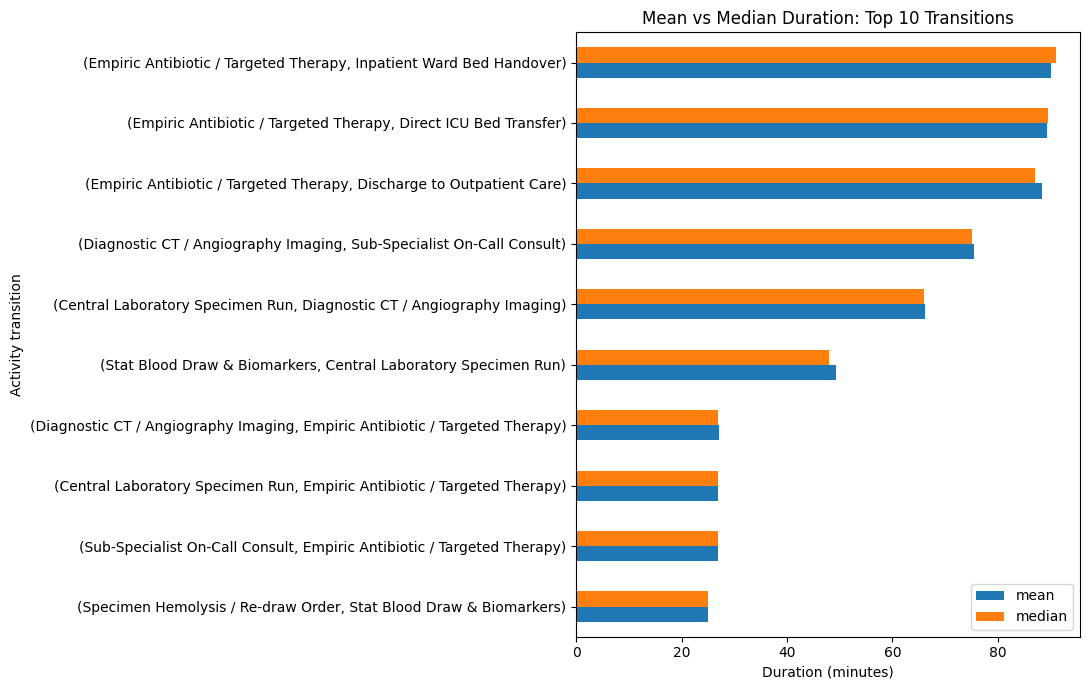

In [ ]:
import matplotlib.pyplot as plt

plot_data = transition_stats.head(10).sort_values("mean")

plot_data[["mean", "median"]].plot(
    kind="barh",
    figsize=(11, 7)
)

plt.xlabel("Duration (minutes)")
plt.ylabel("Activity transition")
plt.title("Mean vs Median Duration: Top 10 Transitions")
plt.tight_layout()
plt.show()

In [ ]:
missing_duration_rows = df[df["Elapsed to Next (min)"].isna()]

print(
    "Cases with missing duration:",
    missing_duration_rows["Case ID"].nunique()
)

print(
    "Missing-duration rows at final event:",
    (
        missing_duration_rows["Event Index"]
        == df.groupby("Case ID")["Event Index"].transform("max")[
            missing_duration_rows.index
        ]
    ).sum()
)

Cases with missing duration: 1428
Missing-duration rows at final event: 1428


findings:
- 8,427 recorded transition durations were available across 9,855 event records.
- The overall mean recorded duration was 42.89 minutes, and the median was 30 minutes.
- The longest recorded duration was 104 minutes.
- The transition from treatment to inpatient ward handover had the highest average duration: 90 minutes across 819 cases.
- Treatment-to-ICU and treatment-to-outpatient transitions also had high average durations.
- These transitions are candidates for further investigation, not confirmed waiting-time bottlenecks.

### Missing-Duration Validation

- Cases with missing transition durations: 1,428
- Missing-duration rows belonging to final events: 1,428

**Finding:** All identified missing-duration rows correspond to final events in their respective cases. Since no subsequent activity exists for these events, the absence of an elapsed-to-next duration is consistent with the event-log structure.

### Conclusion

Transition-time analysis identified treatment-to-ward handover, treatment-to-ICU transfer, treatment-to-outpatient discharge, CT-to-specialist consultation, and laboratory-to-CT transitions as candidates for further investigation based on their recorded elapsed durations.

These results are descriptive. Further validation of timestamp semantics and the meaning of elapsed durations is needed before labeling any transition a confirmed operational bottleneck.

DAY 8

In [ ]:
# Step 1: Review the event-log schema

required_columns = ["Case ID", "Activity", "Timestamp"]
recommended_columns = [
    "Case ID", "Event Index", "Activity", "Timestamp",
    "Next Activity", "Elapsed to Next (min)",
    "Resource", "Department", "Status"
]

print("Dataset shape:", df.shape)

print("\nMissing required columns:")
print([col for col in required_columns if col not in df.columns])

print("\nMissing recommended columns:")
print([col for col in recommended_columns if col not in df.columns])

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values in essential columns:")
display(df[required_columns].isna().sum().to_frame("Missing Values"))

Dataset shape: (9855, 9)

Missing required columns:
[]

Missing recommended columns:
[]

Column data types:
Case ID                               object
Event Index                            int64
Activity                              object
Timestamp                datetime64[ns, UTC]
Next Activity                         object
Elapsed to Next (min)                float64
Resource                              object
Department                            object
Status                                object
dtype: object

Missing values in essential columns:


,Missing Values
Case ID,0
Activity,0
Timestamp,0


In [ ]:
# Step 2: Create a chronologically ordered event log
df = df.sort_values(
    by=["Case ID", "Event Index"]
).reset_index(drop=True)

# Check whether timestamps follow Event Index order
timestamp_diffs = df.groupby("Case ID")["Timestamp"].diff()

out_of_order = timestamp_diffs < pd.Timedelta(0)

print("Total events:", len(df))
print("Events with timestamps earlier than the previous event:",
      out_of_order.sum())

print("\nExamples of out-of-order events:")
display(
    df.loc[out_of_order, ["Case ID", "Event Index", "Activity", "Timestamp"]]
      .head(10)
)

Total events: 9855
Events with timestamps earlier than the previous event: 0

Examples of out-of-order events:


,Case ID,Event Index,Activity,Timestamp


In [ ]:
# Step 3A: Check for duplicate event identifiers
duplicate_events = df.duplicated(
    subset=["Case ID", "Event Index"],
    keep=False
)

print("Duplicate Case ID + Event Index rows:",
      duplicate_events.sum())

# Step 3B: Compare recorded next activity with actual next activity
df["Actual Next Activity"] = (
    df.groupby("Case ID")["Activity"].shift(-1)
)

has_next = df["Actual Next Activity"].notna()

next_activity_mismatch = (
    df.loc[has_next, "Next Activity"]
    != df.loc[has_next, "Actual Next Activity"]
)

print("\nEvents with a next event:",
      has_next.sum())

print("Next Activity mismatches:",
      next_activity_mismatch.sum())

# Display mismatches, if any
display(
    df.loc[
        next_activity_mismatch[next_activity_mismatch].index,
        ["Case ID", "Event Index", "Activity",
         "Next Activity", "Actual Next Activity"]
    ].head(10)
)

# Step 3C: Check terminal events
terminal_events = df.groupby("Case ID").tail(1)

print("\nNumber of cases:", df["Case ID"].nunique())
print("Terminal events:", len(terminal_events))
print("Terminal events with missing Next Activity:",
      terminal_events["Next Activity"].isna().sum())

Duplicate Case ID + Event Index rows: 0

Events with a next event: 8427
Next Activity mismatches: 0


,Case ID,Event Index,Activity,Next Activity,Actual Next Activity



Number of cases: 1428
Terminal events: 1428
Terminal events with missing Next Activity: 1428


In [ ]:
# Step 4A: Remove the temporary validation column
df = df.drop(columns=["Actual Next Activity"])

# Step 4B: Keep the event log in the correct order
df = df.sort_values(
    by=["Case ID", "Event Index"]
).reset_index(drop=True)

# Step 4C: Display the final structure
print("Final dataset shape:", df.shape)
print("\nFinal columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Values"))

# Step 4D: Export the standardized event log
output_file = "careflow_standardized_event_log.csv"
df.to_csv(output_file, index=False)

print("\nExported file:", output_file)

Final dataset shape: (9855, 9)

Final columns:
['Case ID', 'Event Index', 'Activity', 'Timestamp', 'Next Activity', 'Elapsed to Next (min)', 'Resource', 'Department', 'Status']

Missing values:


,Missing Values
Case ID,0
Event Index,0
Activity,0
Timestamp,0
Next Activity,1428
Elapsed to Next (min),1428
Resource,0
Department,0
Status,0



Exported file: careflow_standardized_event_log.csv


## Day 8-9: Event Log Preparation and Standardization

### Objective
Prepare and validate the CareFlow event log before using it for process mining.

### Dataset Overview
- Total events: 9,855
- Unique cases: 1,428
- Total columns: 9
- Essential columns: Case ID, Activity, Timestamp

### Validation Performed
1. Checked the required and recommended columns.
2. Verified that essential columns contain no missing values.
3. Sorted events by Case ID and Event Index.
4. Checked timestamp ordering within each case.
5. Checked duplicate Case ID and Event Index combinations.
6. Compared recorded Next Activity values with actual subsequent activities.
7. Verified terminal events and their missing transition values.

### Results
- No required columns were missing.
- No out-of-order timestamps were found.
- No duplicate event identifiers were found.
- No Next Activity mismatches were found.
- All 1,428 cases had a terminal event with a missing Next Activity.
- The Elapsed to Next (min) column had 1,428 missing values, consistent with terminal events having no subsequent transition.

### Output
Exported the standardized event log as `careflow_standardized_event_log.csv`.

### Conclusion
The event log passed the structural validation checks and is prepared for subsequent process-mining analysis. Structural consistency does not independently establish the clinical correctness or provenance of the dataset.

Day 10 — Introduction to Process Discovery with PM4Py

In [ ]:
# Step 1: Check whether PM4Py is installed
try:
    import pm4py
    print("PM4Py version:", pm4py.__version__)
except ImportError:
    print("PM4Py is not installed.")

PM4Py is not installed.


In [ ]:
%pip install pm4py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 54.0 MB/s eta 0:00:00


In [ ]:
# Step 2: Create a PM4Py-compatible event log

import pandas as pd
import pm4py

# Keep the columns needed for process discovery
event_log = df[
    ["Case ID", "Activity", "Timestamp"]
].copy()

# Rename columns to PM4Py's standard event-log names
event_log = event_log.rename(columns={
    "Case ID": "case:concept:name",
    "Activity": "concept:name",
    "Timestamp": "time:timestamp"
})

# Ensure timestamps are datetime values
event_log["time:timestamp"] = pd.to_datetime(
    event_log["time:timestamp"], utc=True
)

# Sort events into case and time order
event_log = event_log.sort_values(
    by=["case:concept:name", "time:timestamp"]
).reset_index(drop=True)

print("Event log shape:", event_log.shape)
print("\nColumns:", event_log.columns.tolist())
display(event_log.head())

Event log shape: (9855, 3)

Columns: ['case:concept:name', 'concept:name', 'time:timestamp']


,case:concept:name,concept:name,time:timestamp
0,PAT-2026-10000,ED Registration & Triage,2026-10-02 11:20:00+00:00
1,PAT-2026-10000,Initial Physician Assessment,2026-10-02 11:40:00+00:00
2,PAT-2026-10000,Stat Blood Draw & Biomarkers,2026-10-02 12:05:00+00:00
3,PAT-2026-10000,Central Laboratory Specimen Run,2026-10-02 12:45:00+00:00
4,PAT-2026-10000,Empiric Antibiotic / Targeted Therapy,2026-10-02 13:15:00+00:00


In [ ]:
# Step 3: Discover a process tree using Inductive Miner

process_tree = pm4py.discover_process_tree_inductive(
    event_log,
    activity_key="concept:name",
    timestamp_key="time:timestamp",
    case_id_key="case:concept:name"
)

print("Process tree discovered successfully!")
print(process_tree)

Process tree discovered successfully!
->( 'ED Registration & Triage', 'Initial Physician Assessment', *( ->( 'Stat Blood Draw & Biomarkers', 'Central Laboratory Specimen Run' ), 'Specimen Hemolysis / Re-draw Order' ), X( tau, ->( 'Diagnostic CT / Angiography Imaging', X( tau, 'Sub-Specialist On-Call Consult' ) ) ), 'Empiric Antibiotic / Targeted Therapy', X( 'Direct ICU Bed Transfer', 'Discharge to Outpatient Care', 'Inpatient Ward Bed Handover' ) )


In [ ]:
->(
  'ED Registration & Triage',
  'Initial Physician Assessment',
  *(
    ->(
      'Stat Blood Draw & Biomarkers',
      'Central Laboratory Specimen Run'
    ),
    'Specimen Hemolysis / Re-draw Order'
  ),
  X(
    tau,
    ->(
      'Diagnostic CT / Angiography Imaging',
      X(tau, 'Sub-Specialist On-Call Consult')
    )
  ),
  'Empiric Antibiotic / Targeted Therapy',
  X(
    'Direct ICU Bed Transfer',
    'Discharge to Outpatient Care',
    'Inpatient Ward Bed Handover'
  )
)

SyntaxError: invalid syntax (1581439463.py, line 1)

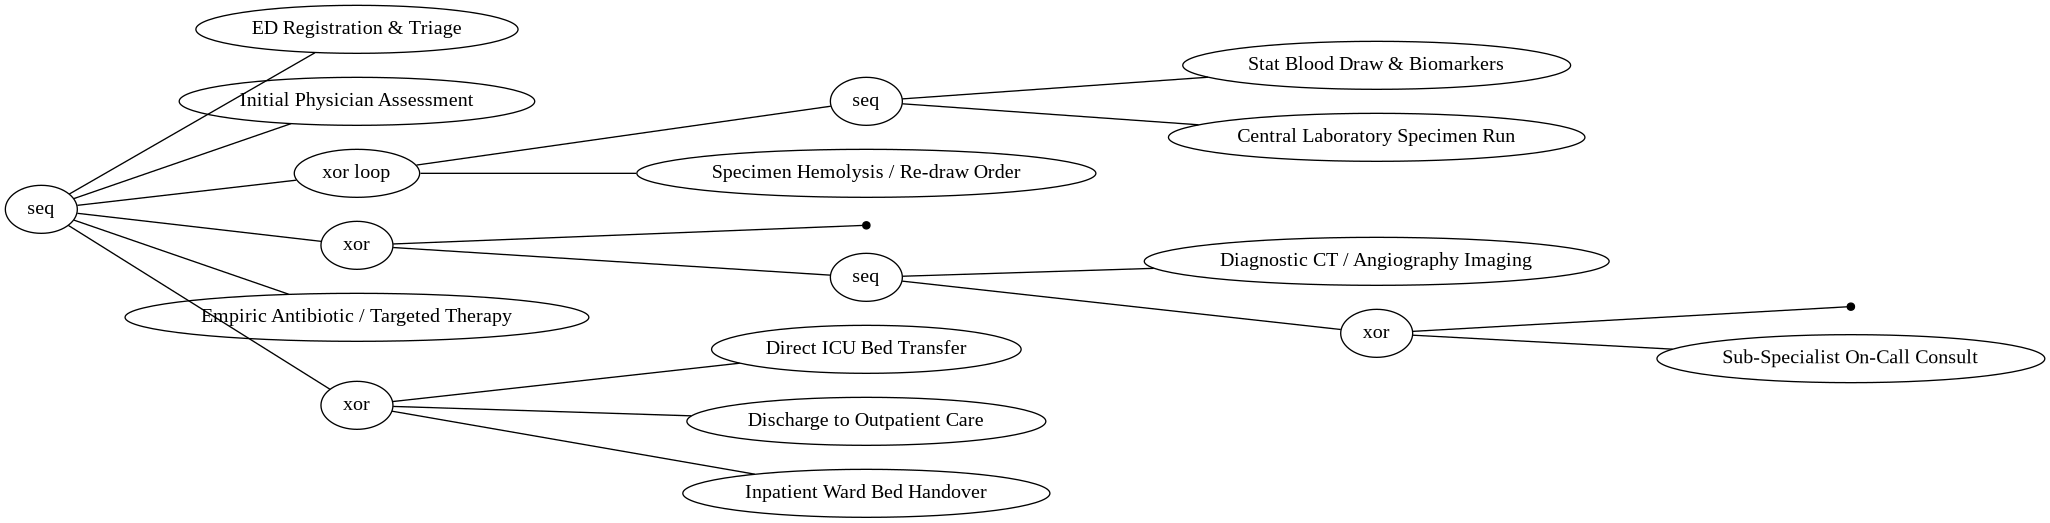

In [ ]:
from pm4py.visualization.process_tree import visualizer as pt_visualizer

# Generate the process tree visualization
gviz = pt_visualizer.apply(process_tree)

# Display the visualization
pt_visualizer.view(gviz)

## Day 10: Process Discovery Using PM4Py

### Objective
Discover a process model from the standardized CareFlow event log using the Inductive Miner algorithm.

### Preparation
Created a PM4Py-compatible event log with the following columns:
- `case:concept:name`
- `concept:name`
- `time:timestamp`

The prepared event log contained 9,855 events.

### Method
Applied `pm4py.discover_process_tree_inductive()` to discover a process tree from the event log.

### Discovered Process Structure
The model includes:
- A sequence of initial registration and physician assessment activities.
- A repeatable laboratory-related structure involving specimen re-draw.
- Optional diagnostic imaging and specialist consultation paths.
- A treatment activity followed by alternative final outcomes.

### Key Process-Tree Operators
- `→`: Sequence
- `*`: Loop
- `X`: Exclusive choice
- `tau`: Silent activity

### Conclusion
The first process tree was successfully discovered using PM4Py. The model provides an initial representation of observed activity sequences and their variations. Further validation and visualization are required before interpreting the model as a representation of the clinical workflow.

DAY 11- Process Model Visualization and Analysis and : Examine common pathways, activity loops, and differences between cases.

In [ ]:
# Day 7 - Step 1: Convert the process tree into a Petri net

net, initial_marking, final_marking = (
    pm4py.convert_to_petri_net(process_tree)
)

print("Petri net created successfully!")
print("Number of places:", len(net.places))
print("Number of transitions:", len(net.transitions))
print("Initial marking:", initial_marking)
print("Final marking:", final_marking)

Petri net created successfully!
Number of places: 10
Number of transitions: 14
Initial marking: ['source:1']
Final marking: ['sink:1']


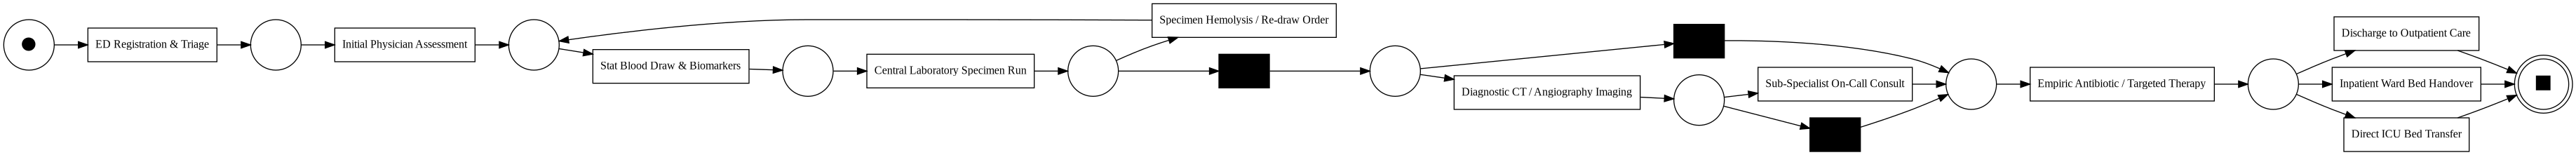

In [ ]:
# Day 7 - Step 2: Visualize the Petri net

from pm4py.visualization.petri_net import visualizer as pn_visualizer

gviz = pn_visualizer.apply(
    net,
    initial_marking,
    final_marking
)

pn_visualizer.view(gviz)

## Day 11: Petri Net Conversion and Visualization, : Examine common pathways, activity loops, and differences between cases.

### Objective
Convert the process tree discovered on Day 6 into a Petri net and visualize the process model.

### Activities Performed
1. Converted the discovered process tree into a Petri net using PM4Py.
2. Retrieved the Petri net, initial marking, and final marking.
3. Counted the places and transitions in the model.
4. Generated a graphical visualization of the Petri net.

### Key Concepts
- **Places:** Represent states or conditions.
- **Transitions:** Represent visible activities or invisible steps.
- **Arcs:** Define connections and possible movement through the model.
- **Initial marking:** Represents the starting state.
- **Final marking:** Represents the desired ending state.

### Interpretation
The discovered model represents a sequence of initial activities, laboratory-related paths, alternative diagnostic activities, treatment, and different final outcomes.

### Conclusion
The CareFlow process tree was successfully converted into a Petri net and visualized using PM4Py. The diagram provides a structural view of the discovered process. Further analysis is needed to evaluate model quality and investigate transition durations or potential bottlenecks.

Additional Analysis — Process Model Evaluation with PM4Py

In [ ]:
# Step 1: Evaluate token-based replay fitness

from pm4py.algo.evaluation.replay_fitness import algorithm as replay_fitness

fitness_result = replay_fitness.apply(
    event_log,
    net,
    initial_marking,
    final_marking,
    variant=replay_fitness.Variants.TOKEN_BASED
)

print("Token-based replay fitness results:")
print(fitness_result)

replaying log with TBR, completed traces ::   0%|          | 0/7 [00:00<?, ?it/s]

Token-based replay fitness results:
{'perc_fit_traces': 100.0, 'average_trace_fitness': 1.0, 'log_fitness': 1.0, 'percentage_of_fitting_traces': 100.0}


In [ ]:
#  Step 2: Check event-log and trace counts

print("Event rows:", len(event_log))

print(
    "Unique cases:",
    event_log["case:concept:name"].nunique()
)

print(
    "Unique activity sequences:",
    event_log.groupby("case:concept:name")["concept:name"]
    .apply(tuple)
    .nunique()
)

Event rows: 9855
Unique cases: 1428
Unique activity sequences: 7


In [ ]:
# Step 3: Evaluate precision

from pm4py.algo.evaluation.precision import algorithm as precision_evaluator

precision_result = precision_evaluator.apply(
    event_log,
    net,
    initial_marking,
    final_marking
)

print("Token-based precision:", precision_result)

computing precision with alignments, completed variants ::   0%|          | 0/13 [00:00<?, ?it/s]

Token-based precision: 0.880354325931319


## Additional Analysis: Process Model Evaluation

### Objective
Evaluate the discovered CareFlow Petri net using replay fitness and precision.

### Methods
1. Token-based replay fitness using PM4Py.
2. Precision evaluation using PM4Py's precision algorithm.

### Results

| Metric | Result |
|---|---:|
| Log fitness | 1.0000 |
| Average trace fitness | 1.0000 |
| Percentage of fitting traces | 100% |
| Token-based precision | 0.8804 |

### Dataset and Variant Summary
- Event rows: 9,855
- Unique cases: 1,428
- Distinct activity sequences in the prepared DataFrame: 7

### Interpretation
The evaluated traces achieved perfect reported token-based replay fitness. The discovered model achieved a precision score of approximately 0.88, indicating that its behavior is not perfectly restricted to the behavior observed in the event log.

The replay and precision operations reported different progress counts (7 and 13 variants, respectively). Their evaluation scopes should be verified before making claims about individual-case coverage.

### Conclusion
The initial process model shows promising replay fitness and reasonably high precision under the selected PM4Py metrics. Further validation is needed before drawing conclusions about the accuracy of the model or the clinical workflow.

In [ ]:

# DAY 11 - Activity Loop Analysis

# 1. Identify cases containing the lab re-draw activity
loop_activity = "Specimen Hemolysis / Re-draw Order"

loop_cases = df.loc[
    df["Activity"] == loop_activity,
    "Case ID"
].unique()

print("Cases containing the lab re-draw loop:", len(loop_cases))

# 2. Calculate cases with and without the loop
total_cases = df["Case ID"].nunique()
cases_without_loop = total_cases - len(loop_cases)

print("Total cases:", total_cases)
print("Cases with loop:", len(loop_cases))
print("Cases without loop:", cases_without_loop)

# 3. Calculate percentage of cases containing the loop
loop_percentage = (len(loop_cases) / total_cases) * 100

print(f"Percentage of cases with loop: {loop_percentage:.2f}%")


Cases containing the lab re-draw loop: 172
Total cases: 1428
Cases with loop: 172
Cases without loop: 1256
Percentage of cases with loop: 12.04%


In [ ]:

# Convert Timestamp from strings to datetime
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

# Verify the datatype
print(df["Timestamp"].dtype)


datetime64[ns, UTC]


In [ ]:

# Create a summary for each case
case_summary = df.groupby("Case ID").agg(
    event_count=("Activity", "count"),
    start_time=("Timestamp", "min"),
    end_time=("Timestamp", "max")
).reset_index()

# Calculate total recorded journey duration in minutes
case_summary["journey_duration_min"] = (
    case_summary["end_time"] - case_summary["start_time"]
).dt.total_seconds() / 60

# Label cases according to whether they contain the loop
case_summary["has_redraw_loop"] = (
    case_summary["Case ID"].isin(loop_cases)
)

# Compare the two groups
loop_comparison = case_summary.groupby("has_redraw_loop").agg(
    number_of_cases=("Case ID", "nunique"),
    avg_events=("event_count", "mean"),
    avg_journey_duration_min=("journey_duration_min", "mean"),
    median_journey_duration_min=("journey_duration_min", "median")
).round(2)

print(loop_comparison)


                 number_of_cases  avg_events  avg_journey_duration_min  \
has_redraw_loop                                                          
False                       1256        6.61                    247.00   
True                         172        9.00                    297.91   

                 median_journey_duration_min  
has_redraw_loop                               
False                                  230.0  
True                                   298.0  


### Day 11 Finding: Impact of the Lab Re-draw Loop

The dataset contains 1,428 cases, of which 172 (12.04%) include the specimen hemolysis/re-draw activity.

Cases containing the re-draw loop have an average of 9 events per case, compared with 6.61 events for cases without the loop. Their average recorded journey duration is 297.91 minutes, compared with 247 minutes for cases without the loop—a difference of approximately 50.91 minutes.

The results indicate that cases containing the re-draw loop tend to have more events and longer recorded journey durations. However, this comparison establishes an association rather than causation. Further investigation would be needed to determine how much of the duration difference is attributable to the loop itself.


In [4]:

# DAY 11 - Differences Between Patient Cases

# Sort events chronologically within each case
df_sorted = df.sort_values(["Case ID", "Timestamp"]).copy()

# Extract the first and last event for each case
case_outcomes = df_sorted.groupby("Case ID").agg(
    first_activity=("Activity", "first"),
    final_activity=("Activity", "last"),
    event_count=("Activity", "count"),
    start_time=("Timestamp", "first"),
    end_time=("Timestamp", "last")
).reset_index()

# Calculate recorded journey duration in minutes
case_outcomes["journey_duration_min"] = (
    case_outcomes["end_time"] - case_outcomes["start_time"]
).dt.total_seconds() / 60

# View the first five cases
case_outcomes.head()


,Case ID,first_activity,final_activity,event_count,start_time,end_time,journey_duration_min
0,PAT-2026-10000,ED Registration & Triage,Inpatient Ward Bed Handover,6,2026-10-02 11:20:00+00:00,2026-10-02 14:40:00+00:00,200.0
1,PAT-2026-10001,ED Registration & Triage,Inpatient Ward Bed Handover,6,2026-10-03 11:37:00+00:00,2026-10-03 15:02:00+00:00,205.0
2,PAT-2026-10002,ED Registration & Triage,Direct ICU Bed Transfer,8,2026-10-04 11:54:00+00:00,2026-10-04 17:28:00+00:00,334.0
3,PAT-2026-10003,ED Registration & Triage,Inpatient Ward Bed Handover,6,2026-10-05 12:11:00+00:00,2026-10-05 15:46:00+00:00,215.0
4,PAT-2026-10004,ED Registration & Triage,Inpatient Ward Bed Handover,7,2026-10-06 12:28:00+00:00,2026-10-06 17:07:00+00:00,279.0


In [5]:

# Count cases by final activity
outcome_counts = (
    case_outcomes["final_activity"]
    .value_counts()
    .rename_axis("Final Activity")
    .reset_index(name="Number of Cases")
)

outcome_counts["Percentage"] = (
    outcome_counts["Number of Cases"]
    / len(case_outcomes) * 100
).round(2)

print(outcome_counts)


                 Final Activity  Number of Cases  Percentage
0   Inpatient Ward Bed Handover              819       57.35
1  Discharge to Outpatient Care              409       28.64
2       Direct ICU Bed Transfer              200       14.01


In [6]:

outcome_duration_summary = case_outcomes.groupby(
    "final_activity"
).agg(
    number_of_cases=("Case ID", "nunique"),
    avg_events=("event_count", "mean"),
    avg_duration_min=("journey_duration_min", "mean"),
    median_duration_min=("journey_duration_min", "median")
).round(2)

print(outcome_duration_summary)


                              number_of_cases  avg_events  avg_duration_min  \
final_activity                                                                
Direct ICU Bed Transfer                   200        8.00            345.12   
Discharge to Outpatient Care              409        6.72            234.11   
Inpatient Ward Bed Handover               819        6.72            240.16   

                              median_duration_min  
final_activity                                     
Direct ICU Bed Transfer                     348.0  
Discharge to Outpatient Care                225.0  
Inpatient Ward Bed Handover                 235.0  


### Day 11 Finding: Differences Between Patient Cases

The 1,428 cases were grouped according to their recorded final activity. Inpatient Ward Bed Handover was the most frequent final activity, accounting for 819 cases (57.35%), followed by Discharge to Outpatient Care with 409 cases (28.64%) and Direct ICU Bed Transfer with 200 cases (14.01%).

ICU-transfer cases had the highest average number of events (8.00) and the longest average recorded journey duration (345.12 minutes). Outpatient-discharge cases had an average duration of 234.11 minutes, while ward-handover cases averaged 240.16 minutes.

These findings show that recorded journey lengths and event counts differ across final-activity groups. The analysis is descriptive and does not establish the cause of these differences. Recorded journey duration should not be interpreted as pure waiting time without validating the timestamp semantics.

**Conclusion:** Comparing final activities, journey lengths, and event counts helps characterize variation in patient-flow patterns and identifies groups for further investigation.


DAY 12

In [7]:

# DAY 12 - Transition-Time Percentile Analysis

# Ensure elapsed durations are numeric
df["Elapsed to Next (min)"] = pd.to_numeric(
    df["Elapsed to Next (min)"],
    errors="coerce"
)

# Keep rows with a valid next activity and duration
valid_transitions = df.dropna(
    subset=[
        "Activity",
        "Next Activity",
        "Elapsed to Next (min)"
    ]
).copy()

# Calculate statistics for each transition
transition_percentiles = (
    valid_transitions
    .groupby(["Activity", "Next Activity"])["Elapsed to Next (min)"]
    .agg(
        sample_count="count",
        mean_minutes="mean",
        median_minutes="median",
        p75_minutes=lambda x: x.quantile(0.75),
        p90_minutes=lambda x: x.quantile(0.90),
        max_minutes="max"
    )
    .reset_index()
    .sort_values("p90_minutes", ascending=False)
    .round(2)
)

print("Valid transitions:", len(valid_transitions))
print("Unique transition types:", len(transition_percentiles))

display(transition_percentiles.head(15))


Valid transitions: 8427
Unique transition types: 13


,Activity,Next Activity,sample_count,mean_minutes,median_minutes,p75_minutes,p90_minutes,max_minutes
7,Empiric Antibiotic / Targeted Therapy,Discharge to Outpatient Care,409,88.33,87.0,96.0,102.0,102.0
6,Empiric Antibiotic / Targeted Therapy,Direct ICU Bed Transfer,200,89.38,89.5,97.0,101.0,104.0
8,Empiric Antibiotic / Targeted Therapy,Inpatient Ward Bed Handover,819,90.00,91.0,97.0,101.0,104.0
4,Diagnostic CT / Angiography Imaging,Sub-Specialist On-Call Consult,200,75.42,75.0,82.0,86.0,88.0
0,Central Laboratory Specimen Run,Diagnostic CT / Angiography Imaging,571,66.24,66.0,72.5,76.0,79.0
11,Stat Blood Draw & Biomarkers,Central Laboratory Specimen Run,1600,49.31,48.0,54.0,57.0,59.0
12,Sub-Specialist On-Call Consult,Empiric Antibiotic / Targeted Therapy,200,26.88,27.0,31.0,33.0,34.0
1,Central Laboratory Specimen Run,Empiric Antibiotic / Targeted Therapy,857,27.00,27.0,31.0,33.0,34.0
3,Diagnostic CT / Angiography Imaging,Empiric Antibiotic / Targeted Therapy,371,27.03,27.0,31.0,33.0,34.0
9,Initial Physician Assessment,Stat Blood Draw & Biomarkers,1428,21.99,22.0,26.0,28.0,29.0


In [8]:

# DAY 12 - Validate Recorded Transition Durations

# Sort events within each case
df_check = df.sort_values(["Case ID", "Timestamp"]).copy()

# Get the next event timestamp within each case
df_check["Next Timestamp"] = (
    df_check.groupby("Case ID")["Timestamp"].shift(-1)
)

# Calculate timestamp-based elapsed minutes
df_check["Calculated Elapsed (min)"] = (
    df_check["Next Timestamp"] - df_check["Timestamp"]
).dt.total_seconds() / 60

# Compare with the recorded elapsed duration
df_check["Duration Difference"] = (
    df_check["Elapsed to Next (min)"]
    - df_check["Calculated Elapsed (min)"]
)

valid_check = df_check.dropna(
    subset=["Elapsed to Next (min)", "Calculated Elapsed (min)"]
)

print("Rows compared:", len(valid_check))
print(
    "Exact matches:",
    (valid_check["Duration Difference"].abs() < 1e-6).sum()
)
print(
    "Mismatches:",
    (valid_check["Duration Difference"].abs() >= 1e-6).sum()
)

display(
    valid_check.loc[
        valid_check["Duration Difference"].abs() >= 1e-6,
        [
            "Case ID", "Activity", "Next Activity",
            "Elapsed to Next (min)", "Calculated Elapsed (min)"
        ]
    ].head(10)
)


Rows compared: 8427
Exact matches: 8427
Mismatches: 0


,Case ID,Activity,Next Activity,Elapsed to Next (min),Calculated Elapsed (min)


### Day 12 Finding: Transition-Duration Validation

The recorded elapsed durations were compared with the time differences between consecutive event timestamps for all 8,427 valid transitions. All 8,427 durations matched exactly, with zero mismatches.

This confirms the internal consistency of the recorded transition durations and supports the reliability of the subsequent descriptive statistical calculations. However, this validation does not independently establish the real-world meaning of the durations or confirm that the identified candidate bottlenecks are operationally caused by delays.

**Conclusion:** The transition-duration calculations passed the timestamp consistency check and can be used for further descriptive analysis, subject to confirmation of the dataset's provenance and duration semantics.
